In [1]:
import pandas as pd
import numpy as np
from statsmodels.tsa.holtwinters import ExponentialSmoothing
import matplotlib.pyplot as plt

In [3]:
# Dados fornecidos
dates = [
    "jul-18", "ago-18", "set-18", "out-18", "nov-18", "dez-18",
    "jan-19", "fev-19", "mar-19", "abr-19", "mai-19", "jun-19",
    "jul-19", "ago-19", "set-19", "out-19", "nov-19", "dez-19",
    "jan-20", "fev-20", "mar-20", "abr-20", "mai-20", "jun-20",
    "jul-20", "ago-20", "set-20", "out-20", "nov-20", "dez-20",
    "jan-21", "fev-21", "mar-21", "abr-21", "mai-21", "jun-21",
    "jul-21", "ago-21", "set-21", "out-21", "nov-21", "dez-21",
    "jan-22", "fev-22", "mar-22", "abr-22", "mai-22", "jun-22",
    "jul-22", "ago-22", "set-22", "out-22", "nov-22", "dez-22",
    "jan-23", "fev-23", "mar-23", "abr-23", "mai-23", "jun-23",
    "jul-23", "ago-23", "set-23", "out-23", "nov-23", "dez-23",
    "jan-24", "fev-24", "mar-24", "abr-24", "mai-24", "jun-24",
    "jul-24", "ago-24", "set-24", "out-24", "nov-24", "dez-24"
]

values = [
    8287.41, 10025.53, 10025.53, 12390.81, 14099.68, 17159.28,
    18670.09, 20674.43, 31599.86, 30692.3, 33508.49, 35242.45,
    34053.24, 21548.77, 30295.05, 33077.27, 28331.14, 32503.4,
    29912.6, 27757.59, 38800.95, 41602.63, 44401.97, 44939.12,
    46086.22, 42165.52, 51181.81, 51925.7, 51156.99, 52927.41,
    54704.2, 54983.47, 72636.78, 74517.18, 76569.33, 77127.96,
    79221.52, 81330.75, 93344.48, 95151.1, 100185.94, 105046.87,
    110393.86, 156738.92, 158887.84, 166604.45, 177242.24, 187324.82,
    195286.52, 203469.41, 224101.56, 224759.62, 231508.24, 240452.21,
    250514.06, 264952.98, 317715.55, 323712.51, 336689.6, 346166.45,
    354341.43, 362632.67, 381485.1, 387149.04, 392438.23, 401900.96,
    401384.67, 405428.8, 477860.68, 472460.23, 484959.87, 498243.91,
    504096.66, 510852.23, 530600.87, 537087.27, 546445.66, 557684.56
]


In [13]:
# Mapeamento de meses em português para números
meses_pt = {
    "jan": "01", "fev": "02", "mar": "03", "abr": "04", "mai": "05", "jun": "06",
    "jul": "07", "ago": "08", "set": "09", "out": "10", "nov": "11", "dez": "12"
}

# Converter os meses de português para números
dates_numeric = [
    f"{meses_pt[date.split('-')[0]]}-20{date.split('-')[1]}"
    for date in dates
]


In [21]:
dates_numeric

['07-2018',
 '08-2018',
 '09-2018',
 '10-2018',
 '11-2018',
 '12-2018',
 '01-2019',
 '02-2019',
 '03-2019',
 '04-2019',
 '05-2019',
 '06-2019',
 '07-2019',
 '08-2019',
 '09-2019',
 '10-2019',
 '11-2019',
 '12-2019',
 '01-2020',
 '02-2020',
 '03-2020',
 '04-2020',
 '05-2020',
 '06-2020',
 '07-2020',
 '08-2020',
 '09-2020',
 '10-2020',
 '11-2020',
 '12-2020',
 '01-2021',
 '02-2021',
 '03-2021',
 '04-2021',
 '05-2021',
 '06-2021',
 '07-2021',
 '08-2021',
 '09-2021',
 '10-2021',
 '11-2021',
 '12-2021',
 '01-2022',
 '02-2022',
 '03-2022',
 '04-2022',
 '05-2022',
 '06-2022',
 '07-2022',
 '08-2022',
 '09-2022',
 '10-2022',
 '11-2022',
 '12-2022',
 '01-2023',
 '02-2023',
 '03-2023',
 '04-2023',
 '05-2023',
 '06-2023',
 '07-2023',
 '08-2023',
 '09-2023',
 '10-2023',
 '11-2023',
 '12-2023',
 '01-2024',
 '02-2024',
 '03-2024',
 '04-2024',
 '05-2024',
 '06-2024',
 '07-2024',
 '08-2024',
 '09-2024',
 '10-2024',
 '11-2024',
 '12-2024']

In [39]:
# Ajustar as datas para o formato correto
data = pd.DataFrame({
    'Date': pd.to_datetime(dates_numeric, errors='coerce'),
    'Value': values
})

data.set_index('Date', inplace=True)
data

C:\Users\diego\AppData\Local\Temp\ipykernel_35016\1619449646.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  'Date': pd.to_datetime(dates_numeric, errors='coerce'),


,Value
Date,
2018-07-01,8287.41
2018-08-01,10025.53
2018-09-01,10025.53
2018-10-01,12390.81
2018-11-01,14099.68
...,...
2024-08-01,510852.23
2024-09-01,530600.87
2024-10-01,537087.27


C:\Users\diego\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\diego\anaconda3\Lib\site-packages\statsmodels\tsa\holtwinters\model.py:918: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(
C:\Users\diego\AppData\Local\Temp\ipykernel_35016\1817901832.py:11: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  future_dates = pd.date_range(start=data.index[-1] + pd.DateOffset(months=1), periods=240, freq='M')


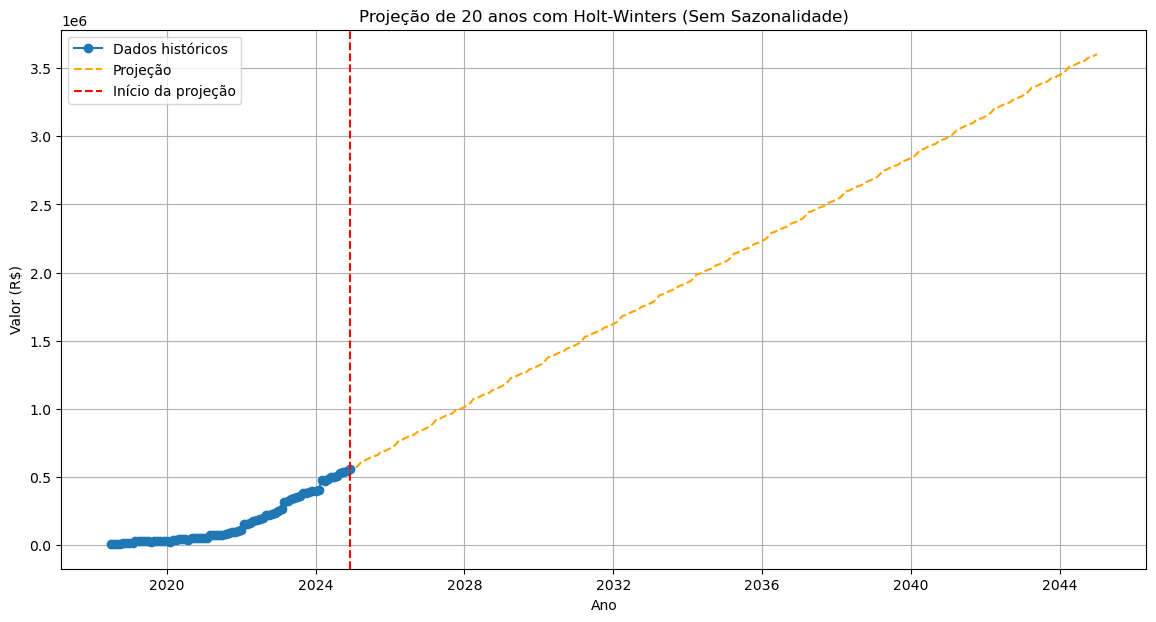

In [43]:


# Modelo de Holt-Winters sem sazonalidade explícita
model = ExponentialSmoothing(
    data['Value'], 
    trend='add',  # Tendência aditiva
    seasonal='add',  # Sazonalidade aditiva
    seasonal_periods=12  # Periodicidade anual (12 meses)
)
fit = model.fit()

# Projeção de 20 anos (240 meses)
future_dates = pd.date_range(start=data.index[-1] + pd.DateOffset(months=1), periods=240, freq='M')
forecast = fit.forecast(len(future_dates))

# Plotagem
plt.figure(figsize=(14, 7))
plt.plot(data.index, data['Value'], label='Dados históricos', marker='o')
plt.plot(future_dates, forecast, label='Projeção', linestyle='--', color='orange')
plt.axvline(data.index[-1], color='red', linestyle='--', label='Início da projeção')
plt.title('Projeção de 20 anos com Holt-Winters (Sem Sazonalidade)')
plt.xlabel('Ano')
plt.ylabel('Valor (R$)')
plt.legend()
plt.grid()
plt.show()



## Modelo 2

C:\Users\diego\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\diego\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\diego\AppData\Local\Temp\ipykernel_35016\1046057138.py:16: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  future_dates = pd.date_range(start=data.index[-1] + pd.DateOffset(months=1), periods=350, freq='M')


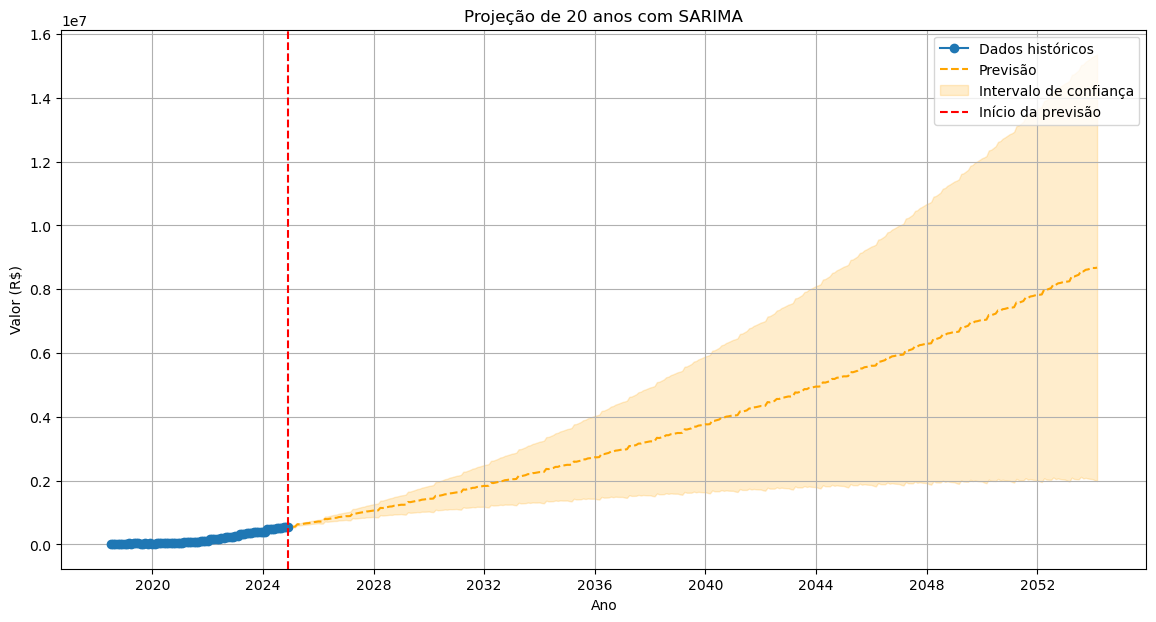

In [55]:
import pandas as pd
import numpy as np
from statsmodels.tsa.statespace.sarimax import SARIMAX
import matplotlib.pyplot as plt
from pandas.tseries.offsets import MonthEnd

# Ajustar os parâmetros do modelo SARIMA
order = (1, 1, 1)  # (p, d, q)
seasonal_order = (1, 1, 1, 12)  # (P, D, Q, s) onde s é a sazonalidade (12 meses)

# Criar e ajustar o modelo SARIMA
model = SARIMAX(data['Value'], order=order, seasonal_order=seasonal_order, enforce_stationarity=False, enforce_invertibility=False)
fit = model.fit(disp=False)

# Fazer previsões para os próximos 20 anos (240 meses)
future_dates = pd.date_range(start=data.index[-1] + pd.DateOffset(months=1), periods=350, freq='M')
forecast = fit.get_forecast(steps=350)
forecast_mean = forecast.predicted_mean
forecast_ci = forecast.conf_int()

# Plotar os dados históricos e previsões
plt.figure(figsize=(14, 7))
plt.plot(data.index, data['Value'], label='Dados históricos', marker='o')
plt.plot(future_dates, forecast_mean, label='Previsão', color='orange', linestyle='--')
plt.fill_between(future_dates, forecast_ci.iloc[:, 0], forecast_ci.iloc[:, 1], color='orange', alpha=0.2, label='Intervalo de confiança')
plt.axvline(data.index[-1], color='red', linestyle='--', label='Início da previsão')
plt.title('Projeção de 20 anos com SARIMA')
plt.xlabel('Ano')
plt.ylabel('Valor (R$)')
plt.legend()
plt.grid()
plt.show()
